<a href="https://colab.research.google.com/github/Bhavya-Chellapandian/online-shoppers-purchasing-intention-dataset/blob/main/Data_Driven_E_Commerce_Purchase_Intention_Analysis_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data-Driven E-Commerce Purchase Intention Analysis Using Python**

## **Stage 1 : Dataset loading and Initial inspection**

# **Dataset Information**

- Dataset name: Online Shoppers Purchasing Intention Dataset
- Source repository: [Bhavya C – online-shoppers-purchasing-intention-dataset](https://github.com/Bhavya-Chellapandian/online-shoppers-purchasing-intention-dataset)
- Original source: [UCI Machine Learning Repository – Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online%2Bshoppers%2Bpurchasing%2Bintention%2Bdatase)
- Domain: Retail / E-commerce / Customer Behaviour
- Expected size: 12,330 sessions and 18 columns.

Dataset citation: Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q.

# **Objective**

1. Understand online shoppers browsing behaviour using session-level data.
2. Explore how administrative, informational, and product-related page visits and time spent relate to purchase outcomes.
3. Examine the distribution of purchasing and non-purchasing sessions using the Revenue target.
4. Compare session characteristics across visitor type, month, weekend status, traffic type, and other categorical attributes.
5. Identify data quality issues and useful patterns to investigate in the next stages of cleaning, statistical analysis, and visualization.
6. Translate the findings into practical recommendations for improving e-commerce conversion.

In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the Dataset from GitHub

url = "https://raw.githubusercontent.com/Bhavya-Chellapandian/online-shoppers-purchasing-intention-dataset/main/online_shoppers_intention.csv"

df = pd.read_csv(url)

# Display the first 5 rows
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# **Initial EDA (Exploratory Data Analysis)**

In [ ]:
# Dataset dimensions and sample records
print("Shape:", df.shape)
print(df.head(10))

Shape: (12330, 18)
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   
5               0                      0.0              0   
6               0                      0.0              0   
7               1                      0.0              0   
8               0                      0.0              0   
9               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0    

In [ ]:
# Column names
print("Column names:")
print(df.columns.tolist())

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [ ]:
# Data types and non-null counts
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  T

In [ ]:
# Descriptive statistics for numerical columns
print("Numerical summary:")
print(df.describe().T)

Numerical summary:
                           count         mean          std  min         25%  \
Administrative           12330.0     2.315166     3.321784  0.0    0.000000   
Administrative_Duration  12330.0    80.818611   176.779107  0.0    0.000000   
Informational            12330.0     0.503569     1.270156  0.0    0.000000   
Informational_Duration   12330.0    34.472398   140.749294  0.0    0.000000   
ProductRelated           12330.0    31.731468    44.475503  0.0    7.000000   
ProductRelated_Duration  12330.0  1194.746220  1913.669288  0.0  184.137500   
BounceRates              12330.0     0.022191     0.048488  0.0    0.000000   
ExitRates                12330.0     0.043073     0.048597  0.0    0.014286   
PageValues               12330.0     5.889258    18.568437  0.0    0.000000   
SpecialDay               12330.0     0.061427     0.198917  0.0    0.000000   
OperatingSystems         12330.0     2.124006     0.911325  1.0    2.000000   
Browser                  12330.0 

In [ ]:
# Summary for categorical / Boolean columns
print("Categorical and Boolean summary:")
print(df.describe(include=["object", "bool"]).T)

Categorical and Boolean summary:
             count unique                top   freq
Month        12330     10                May   3364
VisitorType  12330      3  Returning_Visitor  10551
Weekend      12330      2              False   9462
Revenue      12330      2              False  10422


In [ ]:
# Missing values
print("Missing values by column:")
missing_summary = df.isna().sum().to_frame(name="missing_count")
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
print(missing_summary.sort_values("missing_count", ascending=False))

Missing values by column:
                         missing_count  missing_percent
Administrative                       0              0.0
Administrative_Duration              0              0.0
Informational                        0              0.0
Informational_Duration               0              0.0
ProductRelated                       0              0.0
ProductRelated_Duration              0              0.0
BounceRates                          0              0.0
ExitRates                            0              0.0
PageValues                           0              0.0
SpecialDay                           0              0.0
Month                                0              0.0
OperatingSystems                     0              0.0
Browser                              0              0.0
Region                               0              0.0
TrafficType                          0              0.0
VisitorType                          0              0.0
Weekend               

In [ ]:
# Duplicate rows
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

Exact duplicate rows: 125


In [ ]:
# Numerical and categorical column lists
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

print(f"Numerical columns ({len(numeric_cols)}):", numeric_cols)
print(f"Categorical / Boolean columns ({len(categorical_cols)}):", categorical_cols)

Numerical columns (14): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical / Boolean columns (4): ['Month', 'VisitorType', 'Weekend', 'Revenue']


## **Stage 2: Data Cleaning, Data Transformation and Feature Engineering**

In [ ]:
# Create a working copy
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)
print(df_clean.head())

Original dataset shape: (12330, 18)
Working dataset shape: (12330, 18)
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb         

Handle Duplicate


In [ ]:
# Check the duplicates
duplicate_count = int(df_clean.duplicated().sum())
print(f" duplicate rows found: {duplicate_count:,}")

 duplicate rows found: 125


In [ ]:
# Drop the Duplicates
df_clean = df_clean.drop_duplicates().copy()

print(f"Duplicate rows removed: {duplicate_count:,}")
print("Shape after duplicate removal:", df_clean.shape)

Duplicate rows removed: 125
Shape after duplicate removal: (12205, 18)


Handle Missing Values

In [ ]:
# Missing-value
missing_before = df_clean.isna().sum()
print("Missing Value :",missing_before )

Missing Value : Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


Standardize Column Names and Review Unwanted Columns

In [ ]:
# lowercase and replace spaces
import re

def to_lower_case(column_name):
    name = str(column_name).strip()
    name = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", name)
    name = re.sub(r"[^A-Za-z0-9]+", "_", name)
    return name.strip("_").lower()

original_columns = df_clean.columns.tolist()
df_clean.columns = [to_lower_case(col) for col in df_clean.columns]

print("Column-name changes:")
display(pd.DataFrame({
    "original_name": original_columns,
    "standardized_name": df_clean.columns.tolist()
}))


Column-name changes:


,original_name,standardized_name
0,Administrative,administrative
1,Administrative_Duration,administrative_duration
2,Informational,informational
3,Informational_Duration,informational_duration
4,ProductRelated,product_related
5,ProductRelated_Duration,product_related_duration
6,BounceRates,bounce_rates
7,ExitRates,exit_rates
8,PageValues,page_values
9,SpecialDay,special_day


Data Transformation

In [ ]:
# Normalize text categories; retain the original meaning of each category
for col in df_clean.select_dtypes(include="object"):
    df_clean[col] = df_clean[col].str.strip()

# Convert the target to Boolean only if it is not already Boolean
df_clean["revenue"] = df_clean["revenue"].map(
    lambda x: x if isinstance(x, (bool, np.bool_)) else str(x).strip().lower() == "true"
)

# Validate numerical ranges
rate_cols = ["bounce_rates", "exit_rates"]
for col in rate_cols:
    if col in df_clean:
        print(f"{col}: min={df_clean[col].min():.3f}, max={df_clean[col].max():.3f}")

print("Cleaned shape:", df_clean.shape)

bounce_rates: min=0.000, max=0.200
exit_rates: min=0.000, max=0.200
Cleaned shape: (12205, 18)


Feature engineering

In [ ]:
# Combine the three page categories into session-level browsing measures
df_clean["total_page_views"] = df_clean[["administrative", "informational", "product_related"]].sum(axis=1)
df_clean["total_page_time"] = df_clean[["administrative_duration", "informational_duration",
                               "product_related_duration"]].sum(axis=1)
df_clean["avg_time_per_page"] = df_clean["total_page_time"] / df_clean["total_page_views"].replace(0, np.nan)

# Share of page views by category
for page in ["administrative", "informational", "product_related"]:
    df_clean[f"{page}_view_share"] = df_clean[page] / df_clean["total_page_views"].replace(0, np.nan)

# Simple engagement indicator and readable target label
df_clean["browsed_products"] = df_clean["product_related"] > 0
df_clean["purchase_status"] = np.where(df_clean["revenue"], "Purchase", "No purchase")

print("New features created: total_page_views, total_page_time, avg_time_per_page, "
      "three page-view shares, browsed_products and purchase_status")
print(df_clean[["total_page_views", "total_page_time", "avg_time_per_page",
              "product_related_view_share", "purchase_status"]].head())

New features created: total_page_views, total_page_time, avg_time_per_page, three page-view shares, browsed_products and purchase_status
   total_page_views  total_page_time  avg_time_per_page  \
0                 1         0.000000           0.000000   
1                 2        64.000000          32.000000   
2                 1         0.000000           0.000000   
3                 2         2.666667           1.333333   
4                10       627.500000          62.750000   

   product_related_view_share purchase_status  
0                         1.0     No purchase  
1                         1.0     No purchase  
2                         1.0     No purchase  
3                         1.0     No purchase  
4                         1.0     No purchase  


## **Stage 3 : Statistical analysis and visualizations**

In [ ]:
# Descriptive statistics for the main numeric session measures
numeric_summary_cols = [
    "administrative", "administrative_duration",
    "informational", "informational_duration",
    "product_related", "product_related_duration",
    "total_page_views", "total_page_time", "page_values",
    "bounce_rates", "exit_rates"
]
display(df_clean[numeric_summary_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
administrative,12205.0,2.34,3.33,0.0,0.00,1.00,4.00,27.00
administrative_duration,12205.0,81.65,177.49,0.0,0.00,9.00,94.70,3398.75
informational,12205.0,0.51,1.28,0.0,0.00,0.00,0.00,24.00
informational_duration,12205.0,34.83,141.42,0.0,0.00,0.00,0.00,2549.38
product_related,12205.0,32.05,44.59,0.0,8.00,18.00,38.00,705.00
product_related_duration,12205.0,1206.98,1919.60,0.0,193.00,608.94,1477.15,63973.52
total_page_views,12205.0,34.89,46.63,0.0,9.00,20.00,42.00,746.00
total_page_time,12205.0,1323.45,2043.87,0.0,231.67,690.96,1643.96,69921.65
page_values,12205.0,5.95,18.65,0.0,0.00,0.00,0.00,361.76
bounce_rates,12205.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20


In [ ]:
# Conversion rate by categorical attribute
def conversion_summary(column):
    result = df_clean.groupby(column, dropna=False)["revenue"].agg(
        sessions="count", purchases="sum", conversion_rate="mean"
    )
    result["conversion_%"] = result["conversion_rate"] * 100
    return result.drop(columns="conversion_rate").sort_values("conversion_%", ascending=False)

for col in ["visitor_type", "month", "weekend", "traffic_type", "region"]:
    print(f"\nConversion by {col}:")
    print(conversion_summary(col).round(2))


Conversion by visitor_type:
                   sessions  purchases  conversion_%
visitor_type                                        
New_Visitor            1693        422         24.93
Other                    81         16         19.75
Returning_Visitor     10431       1470         14.09

Conversion by month:
       sessions  purchases  conversion_%
month                                   
Nov        2982        760         25.49
Oct         549        115         20.95
Sep         448         86         19.20
Aug         433         76         17.55
Jul         432         66         15.28
Dec        1706        216         12.66
May        3329        365         10.96
Mar        1860        192         10.32
June        285         29         10.18
Feb         181          3          1.66

Conversion by weekend:
         sessions  purchases  conversion_%
weekend                                   
True         2859        499         17.45
False        9346       1409         15

## online shoppers' browsing behaviour using session-level data

In [ ]:
# Final evidence table for the business insights below
purchase_rate = df_clean["revenue"].mean() * 100
group_medians = df_clean.groupby("purchase_status")[
    ["total_page_views", "total_page_time", "product_related",
     "product_related_duration", "page_values", "bounce_rates", "exit_rates"]
].median()

print(
    f"Overall conversion: {purchase_rate:.2f}% "
    f"({int(df_clean['revenue'].sum()):,} purchases from {len(df_clean):,} sessions)."
)
print("Median session behaviour:")
display(group_medians.T.round(2))

for col in ["visitor_type", "month", "weekend", "traffic_type", "region"]:
    print(f"Conversion by {col}:")
    display(conversion_summary(col).round(2))

# Page-value bands are derived for descriptive segmentation only.
df_clean["page_value_group"] = pd.cut(
    df_clean["page_values"],
    bins=[-0.001, 0, 5, 20, np.inf],
    labels=["Zero", "Low (0–5]", "Medium (5–20]", "High (>20)"]
)
print("Conversion by page-value group:")
display(conversion_summary("page_value_group").round(2))


Overall conversion: 15.63% (1,908 purchases from 12,205 sessions).
Median session behaviour:


purchase_status,No purchase,Purchase
total_page_views,18.00,32.00
total_page_time,600.75,1252.08
product_related,16.00,29.00
product_related_duration,526.00,1109.91
page_values,0.00,16.76
bounce_rates,0.00,0.00
exit_rates,0.03,0.02


Conversion by visitor_type:


,sessions,purchases,conversion_%
visitor_type,,,
New_Visitor,1693,422,24.93
Other,81,16,19.75
Returning_Visitor,10431,1470,14.09


Conversion by month:


,sessions,purchases,conversion_%
month,,,
Nov,2982,760,25.49
Oct,549,115,20.95
Sep,448,86,19.20
Aug,433,76,17.55
Jul,432,66,15.28
Dec,1706,216,12.66
May,3329,365,10.96
Mar,1860,192,10.32
June,285,29,10.18


... (5 outputs left out)

,sessions,purchases,conversion_%
region,,,
9,505,86,17.03
2,1128,188,16.67
1,4714,771,16.36
5,318,52,16.35
7,758,119,15.70
4,1171,175,14.94
3,2379,349,14.67
6,801,112,13.98
8,431,56,12.99


Conversion by page-value group:


/tmp/ipykernel_3747/3426520042.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = df_clean.groupby(column, dropna=False)["revenue"].agg(


,sessions,purchases,conversion_%
page_value_group,,,
High (>20),1170,849,72.56
Medium (5–20],1102,527,47.82
Low (0–5],458,162,35.37
Zero,9475,370,3.91


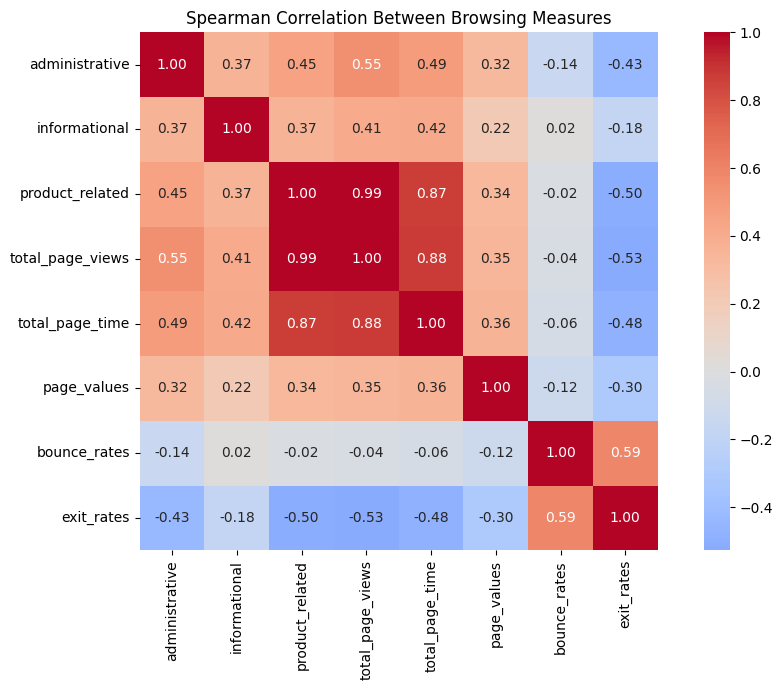

,administrative,informational,product_related,total_page_views,total_page_time,page_values,bounce_rates,exit_rates
administrative,1.00,0.37,0.45,0.55,0.49,0.32,-0.14,-0.43
informational,0.37,1.00,0.37,0.41,0.42,0.22,0.02,-0.18
product_related,0.45,0.37,1.00,0.99,0.87,0.34,-0.02,-0.50
total_page_views,0.55,0.41,0.99,1.00,0.88,0.35,-0.04,-0.53
total_page_time,0.49,0.42,0.87,0.88,1.00,0.36,-0.06,-0.48
page_values,0.32,0.22,0.34,0.35,0.36,1.00,-0.12,-0.30
bounce_rates,-0.14,0.02,-0.02,-0.04,-0.06,-0.12,1.00,0.59
exit_rates,-0.43,-0.18,-0.50,-0.53,-0.48,-0.30,0.59,1.00


In [ ]:
correlation_features = [
    "administrative", "informational", "product_related",
    "total_page_views", "total_page_time", "page_values",
    "bounce_rates", "exit_rates"
]
spearman_corr = df_clean[correlation_features].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True)
plt.title("Spearman Correlation Between Browsing Measures")
plt.tight_layout()
plt.show()
display(spearman_corr.round(2))


Interpretation – Spearman Correlation Heatmap

The heatmap compares the rank-based relationships among the main browsing measures.

- Product-related page views and total page views have a very strong positive correlation (0.99).
- Total page views and total page time are strongly positively correlated (0.88).
- Product-related page views and product-related time are strongly correlated (0.87).
- Bounce rate and exit rate show a moderate positive correlation (0.59).
- Exit rate is negatively correlated with product-related page views (-0.50) and total page views (-0.53).

**Key insight:** Browsing depth and time tend to move together. Correlation describes association, not causation, and some strong relationships are expected because the engineered total measures contain the original page-category measures.

## Compare administrative, informational and product-related page visits for purchasing and non-purchasing sessions.

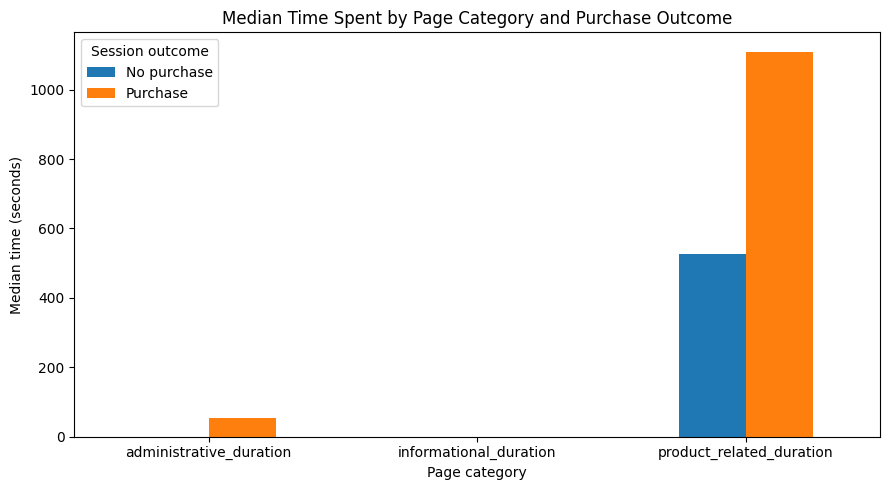

purchase_status,No purchase,Purchase
administrative_duration,0.0,52.37
informational_duration,0.0,0.00
product_related_duration,526.0,1109.91


Interpretation: The largest median time difference is for product related pages (1109.91 seconds purchase vs 526.00 seconds no purchase).


In [ ]:
page_time_cols = [
    "administrative_duration", "informational_duration",
    "product_related_duration"
]
page_time_medians = df_clean.groupby("purchase_status")[page_time_cols].median().T
ax = page_time_medians.plot(kind="bar", figsize=(9, 5))
ax.set_title("Median Time Spent by Page Category and Purchase Outcome")
ax.set_xlabel("Page category")
ax.set_ylabel("Median time (seconds)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Session outcome")
plt.tight_layout()
plt.show()

display(page_time_medians.round(2))
largest_time_gap = (
    page_time_medians["Purchase"] - page_time_medians["No purchase"]
).abs().idxmax()
print(
    f"Interpretation: The largest median time difference is for "
    f"{largest_time_gap.replace('_duration', '').replace('_', ' ')} pages "
    f"({page_time_medians.loc[largest_time_gap, 'Purchase']:.2f} seconds "
    f"purchase vs {page_time_medians.loc[largest_time_gap, 'No purchase']:.2f} "
    f"seconds no purchase)."
)


Interpretation:

Purchasing sessions spend more time on administrative pages (52.37 sec) and product-related pages (1,109.91 sec) than non-purchasing sessions (0 sec and 510.19 sec, respectively).

Key Insight:

Product-related pages show the largest time difference, approximately 599.72 seconds, between the two session groups.

## Examine the distribution of purchasing and non-purchasing sessions using Revenue.

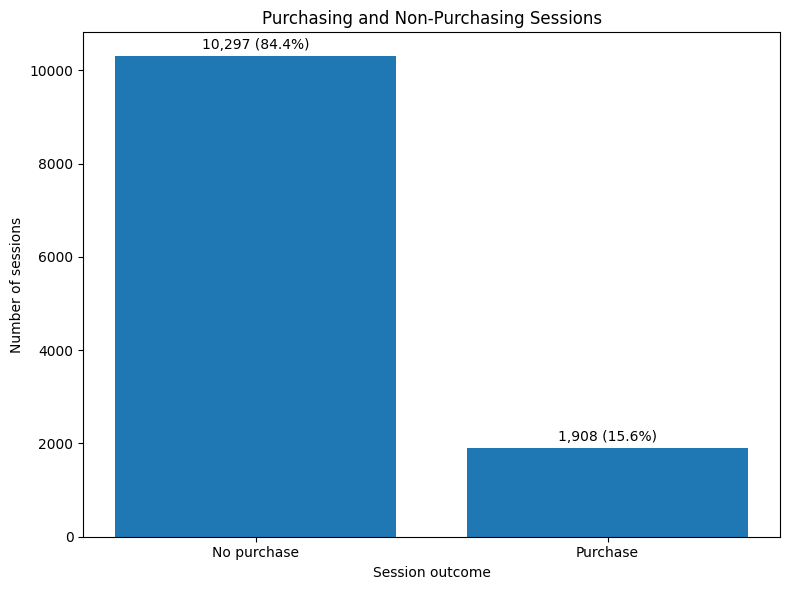

In [ ]:
revenue_counts = df_clean["purchase_status"].value_counts().reindex(
    ["No purchase", "Purchase"]
)
revenue_percent = revenue_counts / len(df_clean) * 100

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(revenue_counts.index, revenue_counts.values)
ax.set_title("Purchasing and Non-Purchasing Sessions")
ax.set_xlabel("Session outcome")
ax.set_ylabel("Number of sessions")
ax.bar_label(
    bars,
    labels=[f"{int(v):,} ({p:.1f}%)"
            for v, p in zip(revenue_counts.values, revenue_percent.values)],
    padding=3
)
plt.tight_layout()
plt.show()


Interpretation:

Out of 12,205 sessions, 1,908 (15.47%) resulted in purchases, while 10,297 (84.37%) did not.

Key Insight:

Non-purchasing sessions are approximately 5.4 times higher than purchasing sessions, indicating scope for improving conversion rates.

## Compare purchase conversion across new, returning and other visitor types.

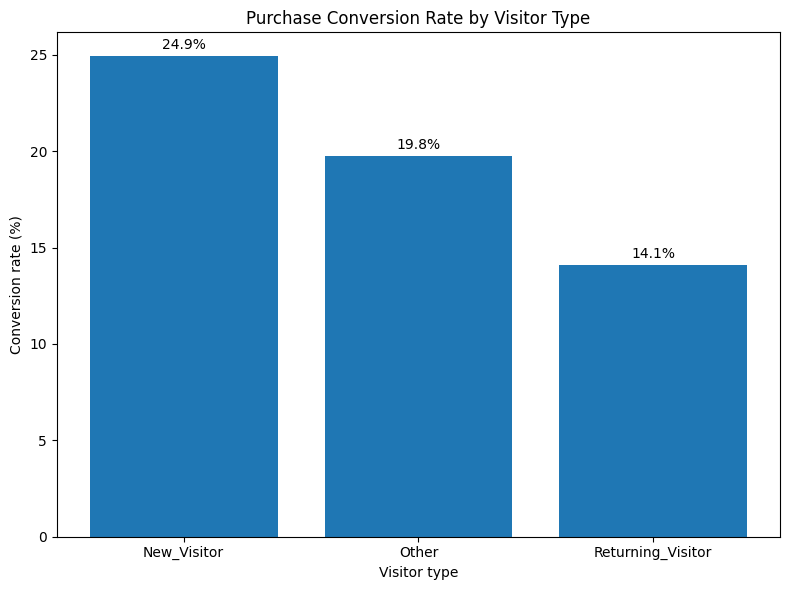

,visitor_type,sessions,conversion_%
0,New_Visitor,1693,24.93
1,Other,81,19.75
2,Returning_Visitor,10431,14.09


In [ ]:
visitor_conversion = conversion_summary("visitor_type").reset_index()
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(visitor_conversion["visitor_type"].astype(str),
               visitor_conversion["conversion_%"])
ax.set_title("Purchase Conversion Rate by Visitor Type")
ax.set_xlabel("Visitor type")
ax.set_ylabel("Conversion rate (%)")
ax.bar_label(
    bars,
    labels=[f"{r:.1f}%" for r in visitor_conversion["conversion_%"]],
    padding=3
)
plt.tight_layout()
plt.show()
display(visitor_conversion[["visitor_type", "sessions", "conversion_%"]].round(2))


Interpretation:

New visitors have the highest conversion rate (24.93%), followed by Other visitors (19.75%) and Returning visitors (14.09%).

Key Insight:

New visitors convert more frequently, while returning visitors represent the majority of sessions (10,551).

## Compare monthly purchase conversion and identify months that may require further seasonal or campaign investigation.

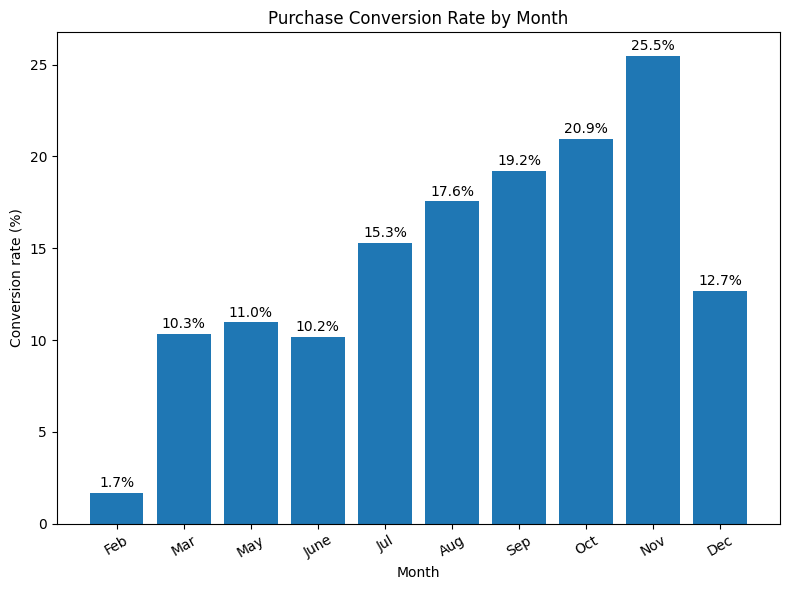

,sessions,purchases,conversion_%
month,,,
Feb,181.0,3.0,1.66
Mar,1860.0,192.0,10.32
May,3329.0,365.0,10.96
June,285.0,29.0,10.18
Jul,432.0,66.0,15.28
Aug,433.0,76.0,17.55
Sep,448.0,86.0,19.20
Oct,549.0,115.0,20.95
Nov,2982.0,760.0,25.49


Highest observed monthly conversion: Nov (25.49%). Lowest: Feb (1.66%). Compare each rate with its session count before drawing conclusions.


In [ ]:
month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "June",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]
monthly_conversion = conversion_summary("month").reindex(month_order).dropna()

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(monthly_conversion.index.astype(str),
               monthly_conversion["conversion_%"])
ax.set_title("Purchase Conversion Rate by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Conversion rate (%)")
ax.tick_params(axis="x", rotation=30)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in monthly_conversion["conversion_%"]],
             padding=2)
plt.tight_layout()
plt.show()

display(monthly_conversion[["sessions", "purchases", "conversion_%"]].round(2))
print(
    f"Highest observed monthly conversion: {monthly_conversion['conversion_%'].idxmax()} "
    f"({monthly_conversion['conversion_%'].max():.2f}%). Lowest: "
    f"{monthly_conversion['conversion_%'].idxmin()} "
    f"({monthly_conversion['conversion_%'].min():.2f}%). "
    "Compare each rate with its session count before drawing conclusions."
)


Interpretation:

November records the highest conversion rate (25.49%), while February has the lowest (1.66%). October also shows a high conversion rate of 20.95%.

Key Insight:

Monthly conversion rates vary considerably, suggesting possible seasonal or campaign-related differences.

## Conversion across weekend, traffic type and region

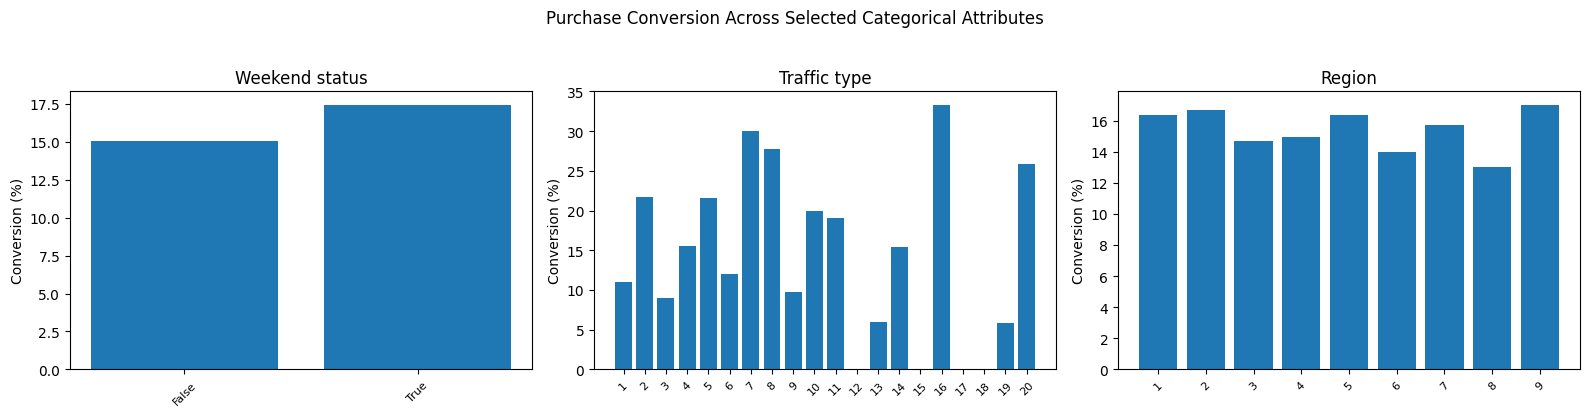

Conversion summary — weekend:


,sessions,purchases,conversion_%
weekend,,,
True,2859,499,17.45
False,9346,1409,15.08


Conversion summary — traffic_type:


,sessions,purchases,conversion_%
traffic_type,,,
16,3,1,33.33
7,40,12,30.00
8,343,95,27.70
20,193,50,25.91
2,3911,847,21.66
5,260,56,21.54
10,450,90,20.00
11,247,47,19.03
4,1066,165,15.48


Conversion summary — region:


,sessions,purchases,conversion_%
region,,,
9,505,86,17.03
2,1128,188,16.67
1,4714,771,16.36
5,318,52,16.35
7,758,119,15.70
4,1171,175,14.94
3,2379,349,14.67
6,801,112,13.98
8,431,56,12.99


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

plot_specs = [
    ("weekend", "Weekend status"),
    ("traffic_type", "Traffic type"),
    ("region", "Region")
]

for ax, (column, title) in zip(axes, plot_specs):
    result = conversion_summary(column).sort_index().reset_index()
    labels = [str(value) for value in result[column]
    ]
    ax.bar(labels, result["conversion_%"])
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Conversion (%)")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

fig.suptitle("Purchase Conversion Across Selected Categorical Attributes", y=1.03)
plt.tight_layout()
plt.show()

for column in ["weekend", "traffic_type", "region"]:
    print(f"Conversion summary — {column}:")
    display(conversion_summary(column).round(2))


Interpretation:

- Weekend: Weekend sessions convert at 17.45%, compared with 15.08% on weekdays.
- Traffic Type: Traffic Type 2 has a 21.66% conversion rate, while Type 13 has 5.91%.
- Region: Region 9 has the highest conversion rate (17.03%), while Region 8 has the lowest (12.99%).
Key Insight:

Weekend sessions show better conversion, and traffic-type and regional differences highlight areas for further investigation.

## **Stage 4 : Key Findings, Business Insights & Recommendations**

### Key Findings

1. **Overall purchase conversion:** 1,908 of 12,205 sessions resulted in a purchase, giving an overall conversion rate of **15.63%**. The remaining 84.37% did not convert.
2. **Browsing depth:** Purchasing sessions had a median of 32 page views, compared with 18 for non-purchasing sessions.
3. **Browsing duration:** Purchasing sessions had a median browsing time of approximately 1,252.08 seconds, compared with 600.75 seconds for non-purchasing sessions.
4. **Product exploration:** Purchasing sessions had a median of 29 product-related page views and 1,109.91 seconds on those pages, compared with 16 views and 526.00 seconds for non-purchasing sessions.
5. **Page value:** Median page value was 16.76 for purchasing sessions and 0 for non-purchasing sessions. Conversion rose from 3.91% in the zero page-value group to 72.56% in the high page-value group.
6. **Visitor type:** New visitors converted at 24.93%, compared with 14.09% for returning visitors. Returning visitors nevertheless represented the largest session group (10,431 sessions).
7. **Monthly pattern:** November had the highest monthly conversion rate (25.49%; 2,982 sessions), while February had the lowest (1.66%; 181 sessions).
8. **Day of week:** Weekend conversion was 17.45%, compared with 15.08% on weekdays.
9. **Traffic and region:** Conversion varied by traffic type and region. Interpret very small traffic-type groups cautiously; for example, the 33.33% rate for Traffic Type 16 came from only 3 sessions. Region 9 was highest (17.03%) and Region 8 lowest (12.99%).
10. **Engagement indicators:** Total page views and total page time had a Spearman correlation of **0.88**. Bounce rate and exit rate had a correlation of **0.59**. These are associations; total page views also contains the page-category counts used to construct it.

### Business Insights

- **Product exploration is associated with purchase outcomes.** Purchasing sessions browse more product-related pages and spend more time on them. Review product information quality, images, comparison features, stock visibility and price clarity to identify opportunities to support product evaluation.
- **Zero page value is a large, low-converting segment.** It contains **9,475 sessions (77.63% of cleaned sessions)** and converts at **3.91%**. Analyze where these sessions leave the journey and whether product discovery, product detail pages or checkout steps create friction. Page value is an observed metric, so do not treat it as a controllable cause without further investigation.
- **Returning visitors offer a high-volume improvement opportunity.** They account for **10,431 sessions** but convert at **14.09%**, below the **24.93%** rate for new visitors. Examine repeat-visit paths, cart recovery, product availability, pricing and checkout usability.
- **Monthly conversion differences deserve validation.** November is strongest in this dataset, but campaign calendars, promotions, seasonality and traffic composition are not included as explanatory evidence. Compare these factors before planning spend around the pattern.
- **Weekend sessions show a higher observed conversion rate.** The difference is 2.37 percentage points (17.45% versus 15.08%). Test whether weekend campaigns or staffing changes improve outcomes rather than assuming the day itself causes conversion.
- **Traffic-type and regional differences can guide investigation.** Traffic Type 13 is a sizeable lower-converting group (728 sessions; 5.91%). Region 8 is also below Region 9. Because the values are coded, obtain the source's code definitions before assigning channel or geographic labels.
- **Use correlation carefully.** Strong correlations among page views and time can reflect the way total features are calculated. They should not be presented as causal evidence.

### Recommendations

1. **Improve product detail pages:** Test clearer product descriptions, high-quality images, transparent pricing, delivery estimates, stock status and customer reviews.
2. **Investigate the non-converting journey:** Build a funnel view from landing page to product page, cart and checkout. Identify the step with the largest drop-off and prioritize usability testing there.
3. **Run a returning-visitor re-engagement test:** Test relevant recommendations, saved-cart reminders and simpler repeat checkout. Measure incremental conversion against a control group.
4. **Audit lower-converting traffic sources:** Review Traffic Type 13 campaign targeting, landing-page relevance and traffic quality. Compare outcomes using adequate sample sizes before reallocating budget.
5. **Validate timing patterns:** Compare weekend and November results with campaign, discount and traffic-mix data. Run controlled tests before changing campaign schedules.
6. **Monitor a consistent KPI set:** Track sessions, purchases, session conversion rate, product-page engagement, cart abandonment and checkout completion over time.
7. **Collect richer business context:** Add campaign identifiers, device details, product/category information and clearly documented region and traffic-type mappings to support more specific recommendations.

### Export the analysis-ready dataset

In [ ]:
df_clean.to_csv("online_shoppers_cleaned_engineered.csv", index=False)
print("Exported: online_shoppers_cleaned_engineered.csv")

Exported: online_shoppers_cleaned_engineered.csv
